# Практическое задание №4. Задача регрессии на Kaggle с помощью линейной регрессии

Цель: разработать алгоритмы машинного обучения, которые позволяют установить связь между химическим составом, различными свойствами сверхпроводниками и их критической температурой.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold, SelectKBest, mutual_info_regression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, GradientBoostingRegressor
import seaborn as sns
from sklearn.preprocessing import StandardScaler, FunctionTransformer

RANDOM_STATE = 42

In [103]:
train_stats = pd.read_csv("train.csv")
test_stats = pd.read_csv("test.csv")

print(train_stats.head())
train_stats.info()
train_stats.describe()

   number_of_elements  mean_atomic_mass  wtd_mean_atomic_mass  \
0                   4         88.944468             57.862692   
1                   5         92.729214             58.518416   
2                   4         88.944468             57.885242   
3                   4         88.944468             57.873967   
4                   4         88.944468             57.840143   

   gmean_atomic_mass  wtd_gmean_atomic_mass  entropy_atomic_mass  \
0          66.361592              36.116612             1.181795   
1          73.132787              36.396602             1.449309   
2          66.361592              36.122509             1.181795   
3          66.361592              36.119560             1.181795   
4          66.361592              36.110716             1.181795   

   wtd_entropy_atomic_mass  range_atomic_mass  wtd_range_atomic_mass  \
0                 1.062396          122.90607              31.794921   
1                 1.057755          122.90607           

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
count,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,...,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000
mean,4.113874,87.534919,73.000381,71.308789,58.599393,1.165500,1.063972,115.443468,33.228642,44.320187,...,3.151430,3.055206,3.054358,1.295344,1.052631,2.042034,1.482988,0.839731,0.673590,34.502993
std,1.437846,29.786319,33.730910,31.166777,36.902657,0.364607,0.401877,54.614167,27.104426,19.993413,...,1.192035,1.045869,1.175579,0.393231,0.380725,1.244305,0.980906,0.485728,0.454975,34.334793
min,1.000000,6.941000,6.423452,5.320573,1.960849,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000210
25%,3.000000,72.383174,52.078254,58.001648,35.228269,0.966676,0.777721,78.353150,16.790394,32.890369,...,2.117647,2.245649,2.091629,1.060857,0.779166,1.000000,0.920000,0.451754,0.307467,5.330000
50%,4.000000,84.841880,60.547264,66.361592,39.821155,1.199541,1.148646,122.906070,26.585389,45.123500,...,2.605455,2.615321,2.429201,1.368922,1.168512,2.000000,1.062857,0.800000,0.500000,20.000000
75%,5.000000,100.404410,85.982586,78.116681,73.075297,1.444537,1.359836,154.119320,38.193007,58.973428,...,4.019566,3.722419,3.914868,1.589027,1.331531,3.000000,1.912000,1.200000,1.020735,63.000000
max,9.000000,208.980400,208.980400,208.980400,208.980400,1.983797,1.958203,207.972460,205.589910,101.019700,...,7.000000,7.000000,7.000000,2.141963,1.949739,6.000000,6.992200,3.000000,3.000000,185.000000


In [104]:
train_formula = pd.read_csv("formula_train.csv")
test_formula = pd.read_csv("formula_test.csv")

print(train_formula.head())
train_formula.info()
train_formula.describe()


     H  He   Li   Be    B    C    N    O    F  Ne  ...   Au   Hg   Tl   Pb  \
0  0.0   0  0.0  0.0  0.0  0.0  0.0  4.0  0.0   0  ...  0.0  0.0  0.0  0.0   
1  0.0   0  0.0  0.0  0.0  0.0  0.0  4.0  0.0   0  ...  0.0  0.0  0.0  0.0   
2  0.0   0  0.0  0.0  0.0  0.0  0.0  4.0  0.0   0  ...  0.0  0.0  0.0  0.0   
3  0.0   0  0.0  0.0  0.0  0.0  0.0  4.0  0.0   0  ...  0.0  0.0  0.0  0.0   
4  0.0   0  0.0  0.0  0.0  0.0  0.0  4.0  0.0   0  ...  0.0  0.0  0.0  0.0   

    Bi  Po  At  Rn  critical_temp                material  
0  0.0   0   0   0           29.0         Ba0.2La1.8Cu1O4  
1  0.0   0   0   0           26.0  Ba0.1La1.9Ag0.1Cu0.9O4  
2  0.0   0   0   0           19.0         Ba0.1La1.9Cu1O4  
3  0.0   0   0   0           22.0       Ba0.15La1.85Cu1O4  
4  0.0   0   0   0           23.0         Ba0.3La1.7Cu1O4  

[5 rows x 88 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17010 entries, 0 to 17009
Data columns (total 88 columns):
 #   Column         Non-Null Count  Dty

,H,He,Li,Be,B,C,N,O,F,Ne,...,Pt,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp
count,17010.000000,17010.0,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.0,...,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.000000,17010.0,17010.0,17010.0,17010.000000
mean,0.018447,0.0,0.011884,0.035189,0.141945,0.376868,0.012462,3.010023,0.015318,0.0,...,0.035000,0.023379,0.036708,0.049646,0.042367,0.200175,0.0,0.0,0.0,34.502993
std,0.287419,0.0,0.125699,0.861767,1.107689,4.357716,0.123290,3.796711,0.136147,0.0,...,0.310635,0.800146,0.205809,0.279357,0.286488,0.656456,0.0,0.0,0.0,34.334793
min,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000210
25%,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,5.330000
50%,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,20.000000
75%,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,6.800000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,63.000000
max,14.000000,0.0,2.600000,40.000000,105.000000,120.000000,5.000000,66.000000,4.000000,0.0,...,5.000000,64.000000,8.000000,7.000000,19.000000,14.000000,0.0,0.0,0.0,185.000000


In [105]:
y = train_stats['critical_temp']
X_stats = train_stats.drop(columns=['critical_temp'])
X_formula = train_formula.drop(columns=['critical_temp', 'material'])

## Анализ данных

Набор данных состоит из двух таблиц:

**Признаки состава сверхпроводников** (82 столбца, 17 010 наблюдений).
Количественные агрегированные признаки, отражающие статистические характеристики химического состава: mean_atomic_mass, std_atomic_mass, entropy_atomic_mass, mean_Valence, std_Valence и другие.

**Состав по химическим элементам** (87 столбцов, 17 010 наблюдений)
Столбцы H, He, Li, ..., Rn показывают долю каждого элемента в сверхпроводнике. 
Большинство столбцов разреженные: многие элементы отсутствуют в большинстве образцов (значения = 0).

**Типы признаков:** все признаки являются количественными (вещественные или целочисленные).

**Пропущенные значения:** все столбцы заполнены полностью.

**Целевая переменная:** critical_temp (критическая температура сверхпроводимости) – непрерывная величина для задачи регрессии. Диапазон значений широк: от ~0 K до 185 K. Распределение не является нормальным: медиана (20 K) значительно ниже среднего (34.5 K), что указывает на правостороннюю асимметрию и наличие соединений с высокой критической температурой.

Количество признаков (169) велико, а химический состав представлен крайне разреженной таблицей. Необходимо сформировать новые осмысленные признаки, масштабировать числовые и выбрать наиболее статистически значимые из них.

In [106]:
def create_domain_specific_features(df_elements, df_stats):
    """
    Создание НОВЫХ признаков на основе доменных знаний о сверхпроводниках
    """
    features = pd.DataFrame(index=df_elements.index)
    
    # ==================== ГРУППЫ ЭЛЕМЕНТОВ ====================
    
    # Определяем группы элементов
    transition_metals = ['Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 
                         'Zn', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 
                         'Ag', 'Cd', 'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 
                         'Au', 'Hg']
    
    rare_earth = ['La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 
                  'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu']
    
    alkaline_earth = ['Be', 'Mg', 'Ca', 'Sr', 'Ba', 'Ra']
    
    alkali_metals = ['Li', 'Na', 'K', 'Rb', 'Cs', 'Fr']
    
    pnictogens = ['N', 'P', 'As', 'Sb', 'Bi']
    
    chalcogens = ['O', 'S', 'Se', 'Te', 'Po']
    
    halogens = ['F', 'Cl', 'Br', 'I', 'At']
    
    # ==================== 1. ПРИЗНАКИ ТИПОВ СВЕРХПРОВОДНИКОВ ====================
    
    # Купратные сверхпроводники (медь-кислородные)
    features['is_cuprate'] = ((df_elements['Cu'] > 0) & 
                               (df_elements['O'] > 0)).astype(int)
    
    # Железные сверхпроводники
    features['is_iron_based'] = ((df_elements['Fe'] > 0) & 
                                  (df_elements['As'] > 0)).astype(int)
    
    # Магниевые дибориды
    features['is_mgb2'] = ((df_elements['Mg'] > 0) & 
                            (df_elements['B'] >= 2)).astype(int)
    
    # Органические сверхпроводники
    features['is_organic'] = ((df_elements['C'] > 0) & 
                               (df_elements['H'] > 0)).astype(int)
    
    # ==================== 2. СТЕХИОМЕТРИЧЕСКИЕ ПРИЗНАКИ ====================
    
    # Общее количество атомов
    features['total_atoms'] = df_elements.sum(axis=1)
    
    # Количество уникальных элементов (альтернатива number_of_elements)
    # Но с другой логикой - это реальное количество ненулевых элементов
    features['num_nonzero_elements'] = (df_elements > 0).sum(axis=1)
    
    # Коэффициент разнообразия (энтропия состава) - НОВЫЙ признак
    composition = df_elements.div(df_elements.sum(axis=1), axis=0)
    composition = composition.replace(0, 1e-10)  # чтобы избежать log(0)
    features['composition_entropy'] = -(composition * np.log(composition)).sum(axis=1)
    
    # Доля кислорода (важно для оксидов)
    features['oxygen_fraction'] = df_elements['O'] / (features['total_atoms'] + 1e-10)
    
    # ==================== 3. НОВЫЕ КОМБИНИРОВАННЫЕ ЭЛЕКТРОННЫЕ ПРИЗНАКИ ====================
    
    # Вместо дублирования существующих, создаем новые комбинации:
    
    # 1. Произведение электроотрицательности и валентности
    if 'mean_Electronegativity' in df_stats.columns and 'mean_Valence' in df_stats.columns:
        features['en_valence_product'] = df_stats['mean_Electronegativity'] * df_stats['mean_Valence']
    
    # 2. Отношение энергии ионизации к атомной массе
    if 'wtd_mean_fie' in df_stats.columns and 'wtd_mean_atomic_mass' in df_stats.columns:
        features['ionization_per_mass'] = df_stats['wtd_mean_fie'] / (df_stats['wtd_mean_atomic_mass'] + 1e-10)
    
    # 3. Нормализованный диапазон электроотрицательности
    if 'range_Electronegativity' in df_stats.columns and 'mean_Electronegativity' in df_stats.columns:
        features['normalized_en_range'] = df_stats['range_Electronegativity'] / (df_stats['mean_Electronegativity'] + 1e-10)
    
    # ==================== 4. КОЛИЧЕСТВЕННЫЕ ПРИЗНАКИ ГРУПП ====================
    
    # Суммарное количество переходных металлов
    available_transition = [tm for tm in transition_metals if tm in df_elements.columns]
    if available_transition:
        features['transition_metal_count'] = df_elements[available_transition].sum(axis=1)
        
        # Разнообразие переходных металлов (сколько разных типов)
        features['transition_metal_diversity'] = (df_elements[available_transition] > 0).sum(axis=1)
    
    # Доля переходных металлов
    features['transition_metal_ratio'] = features['transition_metal_count'] / (features['total_atoms'] + 1e-10)
    
    # Наличие редкоземельных элементов
    available_rare_earth = [re for re in rare_earth if re in df_elements.columns]
    if available_rare_earth:
        features['rare_earth_present'] = (df_elements[available_rare_earth].sum(axis=1) > 0).astype(int)
    
    # Количество pnictogen элементов
    available_pnictogens = [p for p in pnictogens if p in df_elements.columns]
    if available_pnictogens:
        features['pnictogen_count'] = df_elements[available_pnictogens].sum(axis=1)
    
    # Количество chalcogen элементов
    available_chalcogens = [c for c in chalcogens if c in df_elements.columns]
    if available_chalcogens:
        features['chalcogen_count'] = df_elements[available_chalcogens].sum(axis=1)
    
    # ==================== 5. ПРИЗНАКИ ДЛЯ КУПРАТОВ ====================
    
    # Отношение Cu:O для купратов (с обработкой деления на 0)
    if 'Cu' in df_elements.columns and 'O' in df_elements.columns:
        features['cu_o_ratio'] = df_elements['Cu'] / (df_elements['O'].replace(0, 1e-10))
        
        # Взаимодействие Cu и O (произведение)
        features['cu_o_interaction'] = df_elements['Cu'] * df_elements['O']
    
    # Наличие цепочки Cu-O-Cu
    if 'Cu' in df_elements.columns and 'O' in df_elements.columns:
        features['has_cu_o_chain'] = ((df_elements['Cu'] >= 2) & 
                                       (df_elements['O'] >= 1)).astype(int)
    
    # ==================== 6. ПРИЗНАКИ СЛОЖНОСТИ СТРУКТУРЫ ====================
    
    # Отношение максимального элемента к среднему (показатель доминирования)
    max_element = df_elements.max(axis=1)
    mean_element = df_elements.mean(axis=1)
    features['dominance_ratio'] = max_element / (mean_element.replace(0, 1e-10))
    
    # Коэффициент симметрии (близок к 1 для симметричных составов)
    features['symmetry_index'] = 1 - (df_elements.std(axis=1) / (mean_element.replace(0, 1e-10)))
    
    # ==================== 7. НОВЫЕ ФИЗИЧЕСКИЕ ПРИЗНАКИ ====================
    
    # Логарифм средней атомной массы (преобразование)
    if 'wtd_mean_atomic_mass' in df_stats.columns:
        features['log_weighted_mass'] = np.log1p(df_stats['wtd_mean_atomic_mass'])
    
    # Квадрат средней валентности
    if 'mean_Valence' in df_stats.columns:
        features['valence_squared'] = df_stats['mean_Valence'] ** 2
    
    # Суммарная энтропия свойств (комбинация разных энтропий)
    entropy_cols = [col for col in df_stats.columns if 'entropy' in col.lower() and col != 'critical_temp']
    if entropy_cols:
        features['total_property_entropy'] = df_stats[entropy_cols].mean(axis=1)
    
    # ==================== 8. БИНАРНЫЕ И ТЕРНАРНЫЕ СИСТЕМЫ ====================
    
    # Признаки на основе количества ненулевых элементов
    features['is_binary'] = (features['num_nonzero_elements'] == 2).astype(int)
    features['is_ternary'] = (features['num_nonzero_elements'] == 3).astype(int)
    features['is_quaternary'] = (features['num_nonzero_elements'] == 4).astype(int)
    features['is_complex'] = (features['num_nonzero_elements'] > 4).astype(int)
    
    # ==================== 9. ПРИЗНАКИ НА ОСНОВЕ ИЗВЕСТНЫХ СЕМЕЙСТВ ====================
    
    # Y-Ba-Cu-O система (обобщенный признак)
    ybco_elements = ['Y', 'Ba', 'Cu', 'O']
    if all(elem in df_elements.columns for elem in ybco_elements):
        features['is_ybco_family'] = ((df_elements['Y'] > 0) | (df_elements['Ba'] > 0)) & \
                                      (df_elements['Cu'] > 0) & (df_elements['O'] > 0)
        features['is_ybco_family'] = features['is_ybco_family'].astype(int)
    
    # Bi-Sr-Ca-Cu-O система
    bscco_elements = ['Bi', 'Sr', 'Ca', 'Cu', 'O']
    if all(elem in df_elements.columns for elem in bscco_elements):
        features['is_bscco_family'] = (df_elements['Bi'] > 0) & (df_elements['Sr'] > 0) & \
                                       (df_elements['Ca'] > 0) & (df_elements['Cu'] > 0) & \
                                       (df_elements['O'] > 0)
        features['is_bscco_family'] = features['is_bscco_family'].astype(int)
    
    # Hg-Ba-Ca-Cu-O система
    hbcco_elements = ['Hg', 'Ba', 'Ca', 'Cu', 'O']
    if all(elem in df_elements.columns for elem in hbcco_elements):
        features['is_hbc_co_family'] = (df_elements['Hg'] > 0) & (df_elements['Ba'] > 0) & \
                                        (df_elements['Ca'] > 0) & (df_elements['Cu'] > 0) & \
                                        (df_elements['O'] > 0)
        features['is_hbc_co_family'] = features['is_hbc_co_family'].astype(int)
    
    # ==================== 10. МЕТАЛЛ-НЕМЕТАЛЛ ОТНОШЕНИЯ ====================
    
    # Списки металлов и неметаллов
    metals = [col for col in df_elements.columns if col not in 
              ['H', 'He', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Si', 'P', 'S', 
               'Cl', 'Ar', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Sb', 'Te', 'I', 
               'Xe', 'At', 'Rn']]
    
    non_metals = [col for col in df_elements.columns if col not in metals]
    
    if metals and non_metals:
        total_metals = df_elements[metals].sum(axis=1)
        total_non_metals = df_elements[non_metals].sum(axis=1)
        features['metal_to_nonmetal_ratio'] = total_metals / (total_non_metals.replace(0, 1e-10))
    
    # ==================== 11. ПРИЗНАКИ ОСНОВНЫХ КОМПОНЕНТОВ ====================
    
    # Доля наиболее распространенного элемента
    features['max_component_fraction'] = max_element / (features['total_atoms'] + 1e-10)
    
    # Индекс однородности (близок к 1 при равномерном распределении)
    features['uniformity_index'] = 1 / (features['num_nonzero_elements'] * features['composition_entropy'].replace(0, 1e-10))
    
    # ==================== 12. ПРОИЗВОДНЫЕ ОТ СУЩЕСТВУЮЩИХ ПРИЗНАКОВ ====================
    
    # Комбинированный признак "сверхпроводящий потенциал"
    if all(col in df_stats.columns for col in ['mean_Electronegativity', 'mean_Valence', 'wtd_mean_atomic_mass']):
        features['superconducting_potential'] = (
            df_stats['mean_Electronegativity'] * 
            df_stats['mean_Valence'] / 
            np.sqrt(df_stats['wtd_mean_atomic_mass'] + 1e-10)
        )
    
    # Нормализованный разброс атомных радиусов
    if all(col in df_stats.columns for col in ['std_atomic_radius', 'mean_atomic_radius']):
        features['normalized_radius_dispersion'] = (
            df_stats['std_atomic_radius'] / (df_stats['mean_atomic_radius'] + 1e-10)
        )
    
    return features

new_features = create_domain_specific_features(X_formula, X_stats)

In [107]:
# Объединяем все признаки в один датафрейм
X = pd.concat([new_features, X_formula, X_stats], axis=1)

print(f"До VarianceThreshold: {X.shape[1]} признаков")
# Удаление низковариативных признаков
selector_var = VarianceThreshold(threshold=0.01)
X_filtered = selector_var.fit_transform(X)
print(f"После VarianceThreshold: {X_filtered.shape[1]} признаков")

# Масштабируем все признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered) 

До VarianceThreshold: 201 признаков
После VarianceThreshold: 184 признаков


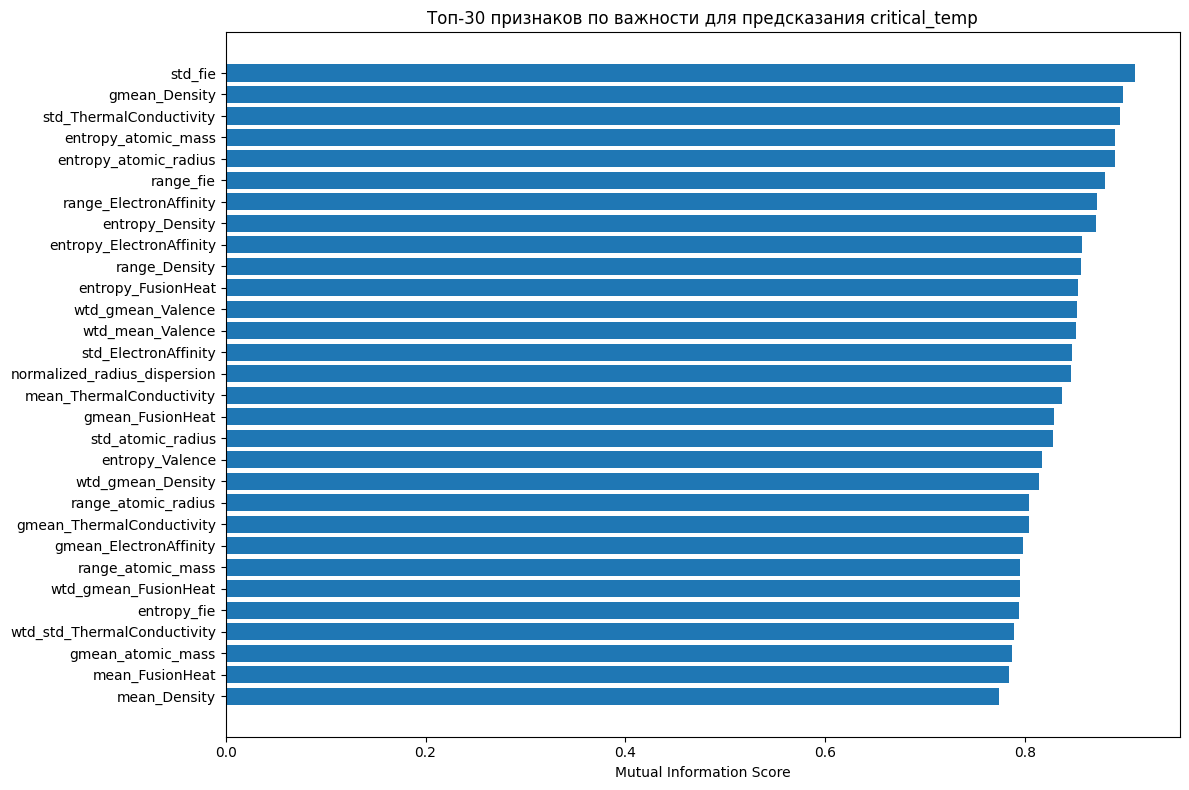

In [ ]:
# Сначала посмотрим оценку ВСЕХ признаков
mi_scores = mutual_info_regression(X_scaled, y)

# Создаем DataFrame для наглядности
mi_df = pd.DataFrame({
    'feature': X.columns[selector_var.get_support()],  # названия 185 признаков
    'mi_score': mi_scores
})

# Сортируем по убыванию важности
mi_df = mi_df.sort_values('mi_score', ascending=False)

# Визуализируем
plt.figure(figsize=(12, 8))
plt.barh(range(30), mi_df['mi_score'].head(30)[::-1])
plt.yticks(range(30), mi_df['feature'].head(30)[::-1])
plt.xlabel('Mutual Information Score')
plt.title('Топ-30 признаков по важности для предсказания critical_temp')
plt.tight_layout()
plt.show()

In [ ]:
# 1. SelectKBest
k_best = 40
selector = SelectKBest(
    score_func=mutual_info_regression,
    k=k_best
)

selector.fit(X_scaled, y)

# 2. Имена признаков 
feature_names_after_var = X.columns[selector_var.get_support()]

selected_features = feature_names_after_var[selector.get_support()]
X_stage1 = X[selected_features]

# 3. Группы признаков
feature_groups = {}

for col in new_features.columns:
    feature_groups[col] = 'engineered'

for col in X_formula.columns:
    feature_groups[col] = 'formula'

for col in X_stats.columns:
    feature_groups[col] = 'stats'
feature_groups_stage1 = feature_groups.copy()

# 4. Итоговая таблица
selected_df = pd.DataFrame({
    'feature': selected_features,
    'group': [feature_groups[f] for f in selected_features]
})

selected_df.head()


,feature,group
0,normalized_radius_dispersion,engineered
1,gmean_atomic_mass,stats
2,entropy_atomic_mass,stats
3,range_atomic_mass,stats
4,std_atomic_mass,stats


Признаки, оказывающие влияние:
- энтропия атомных свойств;
- стандартные отклонения энергетических и атомных характеристик;
- валентность.

Из созданных признаков лишь один (normalized_radius_dispersion) оказался информативным, причём он не основан на исходной таблице элементов, а получен на основе агрегированных метрик.

Вывод: на основе этих наблюдений целесообразно добавить новые признаки и повторно выполнить отбор для улучшения модели.

In [ ]:
# Добавить новые признаки на основе анализа важности признаков
def create_better_features(df_stats):
    """Создаем признаки на основе insights из MI анализа"""
    new_better = pd.DataFrame(index=df_stats.index)
    
    # Комбинации важных признаков
    if all(col in df_stats.columns for col in ['std_fie', 'entropy_atomic_mass']):
        new_better['std_fie_entropy_mass_interaction'] = df_stats['std_fie'] * df_stats['entropy_atomic_mass']
    
    if all(col in df_stats.columns for col in ['entropy_atomic_mass', 'entropy_Valence']):
        new_better['mass_valence_entropy_product'] = df_stats['entropy_atomic_mass'] * df_stats['entropy_Valence']
    
    # Отношения важных признаков
    if all(col in df_stats.columns for col in ['std_fie', 'mean_fie']):
        new_better['fie_variation_coefficient'] = df_stats['std_fie'] / (df_stats['mean_fie'] + 1e-10)
    
    # Квадраты важных признаков
    if 'std_fie' in df_stats.columns:
        new_better['std_fie_squared'] = df_stats['std_fie'] ** 2
    
    return new_better

# Перезапустить отбор признаков с улучшенными признаками
better_features = create_better_features(X_stats)
for col in better_features.columns:
    feature_groups[col] = 'engineered'
X_stage2 = pd.concat([X_stage1, better_features], axis=1)
print(f"До VarianceThreshold: {X_stage2.shape[1]} признаков")
# Удаление низковариативных признаков
X_filtered = selector_var.fit_transform(X_stage2)
print(f"После VarianceThreshold: {X_filtered.shape[1]} признаков")

# Масштабируем все признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered) 

До VarianceThreshold: 44 признаков
После VarianceThreshold: 44 признаков


In [141]:
mi_scores = mutual_info_regression(X_scaled, y)

# Создаем DataFrame для наглядности
mi_df = pd.DataFrame({
    'feature': X_stage2.columns,
    'mi_score': mi_scores
})
mi_df['group'] = mi_df['feature'].map(feature_groups)

# Сортируем по убыванию важности
mi_df = mi_df.sort_values('mi_score', ascending=False).reset_index(drop=True)
mi_df['rank'] = mi_df.index + 1
mi_df.head(20)

,feature,mi_score,group,rank
0,std_fie,0.909736,stats,1
1,gmean_Density,0.898671,stats,2
2,std_ThermalConductivity,0.896767,stats,3
3,mass_valence_entropy_product,0.895408,engineered,4
4,std_fie_entropy_mass_interaction,0.894124,engineered,5
5,entropy_atomic_radius,0.889163,stats,6
6,entropy_atomic_mass,0.887380,stats,7
7,range_fie,0.881526,stats,8
8,range_ElectronAffinity,0.878688,stats,9
9,std_fie_squared,0.873277,engineered,10


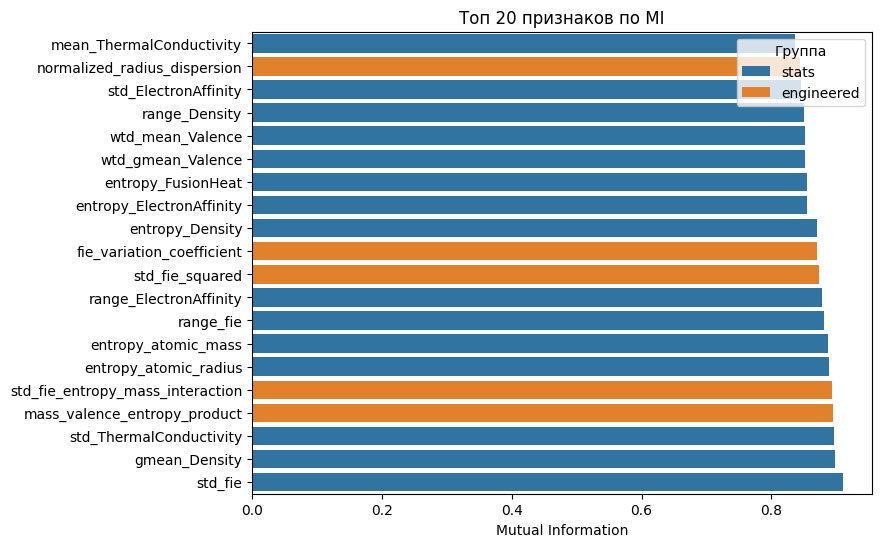

In [142]:
# Топ-20 признаков по MI
top20 = mi_df.sort_values('mi_score', ascending=False).head(20)

plt.figure(figsize=(8,6))
sns.barplot(x='mi_score', y='feature', data=top20, hue='group', dodge=False)
plt.xlabel("Mutual Information")
plt.ylabel("")
plt.title("Топ 20 признаков по MI")
plt.gca().invert_yaxis()
plt.legend(title='Группа')
plt.show()


In [ ]:
# Выбираем K лучших признаков
k_best = 40
selector = SelectKBest(score_func=mutual_info_regression, k=k_best)
X_final_selected = selector.fit_transform(X_scaled, y)

# Имена выбранных признаков
selected_features = X_stage2.columns[selector.get_support()]

# Добавляем новые признаки второго этапа
for col in better_features.columns:
    feature_groups[col] = 'engineered' 

# Таблица для анализа
selected_df = pd.DataFrame({
    'feature': selected_features
})
selected_df['group'] = selected_df['feature'].map(feature_groups)

print(selected_df['group'].isna().sum())

selected_df.head()

0


,feature,group
0,normalized_radius_dispersion,engineered
1,gmean_atomic_mass,stats
2,entropy_atomic_mass,stats
3,range_atomic_mass,stats
4,entropy_fie,stats


## Итоги по обработке признаков

Химический состав представлен крайне разреженной таблицей и обладает высокой размерностью, поэтому его прямое использование приводит к шуму и избыточности. В связи с этим был выполнен доменно-ориентированный feature engineering, направленный на извлечение физически осмысленных агрегированных характеристик состава.

На **первом этапе** были сформированы признаки, отражающие:

- сложность и неоднородность состава (энтропии, стандартные отклонения свойств);

- электронные характеристики и валентность;

- принадлежность к химическим семействам и известным типам сверхпроводников.

После объединения признаков выполнено удаление низкодисперсионных признаков и стандартизация данных.

Анализ значимости признаков с использованием Mutual Information показал, что наибольший вклад вносят **энтропии** и **меры разброса атомных свойств**, в частности стандартное отклонение электроотрицательности и энтропии атомной массы и валентности. При этом признаки, напрямую основанные на разреженном представлении химической формулы, не вошли в число наиболее значимых, поскольку агрегированные статистики эффективно кодируют информацию о составе.

На **втором этапе** feature engineering, опираясь на выявленные закономерности, были сконструированы дополнительные комбинированные признаки, отражающие взаимодействия и нелинейности между наиболее информативными характеристиками. Повторный анализ значимости показал, что несколько из них вошли в число лидирующих:

Созданные признаки и их вклад:
- std_fie_entropy_mass_interaction — 4 место (MI ≈ 0.894), отражает совместное влияние разброса электроотрицательности и разнообразия атомных масс;
- mass_valence_entropy_product — 5 место (MI ≈ 0.893), характеризует электронное и структурное разнообразие состава;
- fie_variation_coefficient — 11 место (MI ≈ 0.870), относительная неоднородность электроотрицательности;
- std_fie_squared — 10 место (MI ≈ 0.874), учитывает нелинейное влияние контраста электроотрицательности;
- normalized_radius_dispersion — 18 место (MI ≈ 0.848), учитывает разброс атомного радиуса.

Таким образом, целенаправленное создание признаков на основе результатов анализа значимости позволило получить небольшое число высокоинформативных признаков, превосходящих по вкладу исходные признаки состава.

Имена итоговых отобранных признаков сохранены и будут использоваться в итоговом пайплайне.

**Ключевой вывод:**
критическая температура сверхпроводников определяется прежде всего неоднородностью и разнообразием электронных и атомных свойств, а не наличием отдельных элементов, причём комбинации и взаимодействия этих характеристик играют решающую роль.

In [ ]:
# Разделяем данные
X = X_final_selected 
y = train_stats['critical_temp'].values


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True
)
print(f"Размеры выборок:")
print(f"Обучающая: {X_train.shape}")
print(f"Тестовая: {X_test.shape}")

Размеры выборок:
Обучающая: (13608, 40)
Тестовая: (3402, 40)


In [115]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
    }

# Быстрая оценка всех моделей
print("Базовая оценка моделей (5-fold CV)")

results = {}
for name, model in models.items():
    # Кросс-валидация
    cv_scores = cross_val_score(model, X_train, y_train, 
                                cv=5, scoring='neg_mean_absolute_error',
                                n_jobs=-1)
    
    mae_cv = -cv_scores.mean()
    std_cv = cv_scores.std()
    
    # Обучаем на полных данных для feature importance
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Метрики на тесте
    mae_test = mean_absolute_error(y_test, y_pred)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
    r2_test = r2_score(y_test, y_pred)
    
    results[name] = {
        'model': model,
        'mae_cv': mae_cv,
        'std_cv': std_cv,
        'mae_test': mae_test,
        'rmse_test': rmse_test,
        'r2_test': r2_test
    }
    
    print(f"\n{name}:")
    print(f"  CV MAE: {mae_cv:.2f} ± {std_cv:.2f} K")
    print(f"  Test MAE: {mae_test:.2f} K")
    print(f"  Test RMSE: {rmse_test:.2f} K")
    print(f"  Test R²: {r2_test:.3f}")

Базовая оценка моделей (5-fold CV)

Linear Regression:
  CV MAE: 14.98 ± 0.29 K
  Test MAE: 14.71 K
  Test RMSE: 19.32 K
  Test R²: 0.672

Ridge:
  CV MAE: 14.99 ± 0.29 K
  Test MAE: 14.71 K
  Test RMSE: 19.32 K
  Test R²: 0.672

Lasso:
  CV MAE: 15.44 ± 0.29 K
  Test MAE: 15.08 K
  Test RMSE: 19.68 K
  Test R²: 0.660

Random Forest:
  CV MAE: 5.70 ± 0.21 K
  Test MAE: 5.31 K
  Test RMSE: 9.46 K
  Test R²: 0.921

Extra Trees:
  CV MAE: 5.45 ± 0.16 K
  Test MAE: 4.98 K
  Test RMSE: 9.15 K
  Test R²: 0.926

Gradient Boosting:
  CV MAE: 9.07 ± 0.30 K
  Test MAE: 8.96 K
  Test RMSE: 13.03 K
  Test R²: 0.851


Линейные модели не смогли адекватно описать зависимость критической температуры от химического состава, что указывает на выраженную нелинейность задачи. Наилучшее качество показали ансамбли деревьев решений, особенно Extra Trees, обеспечившие наименьшую ошибку и высокую обобщающую способность. Это подтверждает, что ключевую роль играют взаимодействия и неоднородность атомных свойств в составе сверхпроводников.

Далее выполняем подбор гиперпараметров с помощью RandomizedSearchC.

In [116]:
best_models = {
    'Random Forest': RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}
print("Подбор гиперпараметров для лучших моделей...")

# Параметры для каждой модели
param_grids = {
    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', 0.5, 0.8]
    },
    
    'Extra Trees': {
        'n_estimators': [100, 200, 300],
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', 0.5, 0.8]
    },
    
    'Gradient Boosting': {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [3, 4, 5, 6],
        'subsample': [0.6, 0.8, 1.0],
        'min_samples_split': [2, 5, 10]
    }
}

# Словарь для сохранения лучших моделей и их параметров
best_tuned_models = {}

for model_name, model in best_models.items():
    print(f"\nНастраиваем {model_name}...")
    
    # Используем RandomizedSearchCV для скорости
    random_search = RandomizedSearchCV(
        model,
        param_grids[model_name],
        n_iter=30,  # пробуем 30 комбинаций
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbose=1
    )
    
    random_search.fit(X_train, y_train)
    
    print(f"* Лучшие параметры для {model_name}:")
    for param, value in random_search.best_params_.items():
        print(f"   {param}: {value}")
    print(f"   Лучший CV MAE: {-random_search.best_score_:.2f} K")
    
    # Сохраняем лучшую модель
    best_tuned_models[model_name] = {
        'model': random_search.best_estimator_,
        'params': random_search.best_params_,
        'cv_score': -random_search.best_score_
    }

Подбор гиперпараметров для лучших моделей...

Настраиваем Random Forest...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
* Лучшие параметры для Random Forest:
   n_estimators: 200
   min_samples_split: 2
   min_samples_leaf: 1
   max_features: sqrt
   max_depth: None
   Лучший CV MAE: 5.72 K

Настраиваем Extra Trees...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
* Лучшие параметры для Extra Trees:
   n_estimators: 300
   min_samples_split: 5
   min_samples_leaf: 1
   max_features: 0.5
   max_depth: 30
   Лучший CV MAE: 5.55 K

Настраиваем Gradient Boosting...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
* Лучшие параметры для Gradient Boosting:
   subsample: 0.8
   n_estimators: 300
   min_samples_split: 5
   max_depth: 6
   learning_rate: 0.1
   Лучший CV MAE: 6.20 K


После проведенного исследования и подбора гиперпараметров необходимо создать финальный пайплайн, выполняющий только необходимые шаги из рассмотренных выше:
- создание признаков(только тех признаков, которые попали в маску отобранных);
- отбор признаков, согласно сформированному ранее списку;
- масштабирование;
- модель, заданная с лучшими гиперпараметрами из RandomizedSearchCV.

In [136]:
# Список итоговых признаков, выбранных после второго отбора
selected_feature_names = list(selected_features) 

def final_feature_engineering(X):
    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(X, columns=X_stats.columns)
    
    features = X.copy()
    # Добавляем улучшенные признаки
    features['std_fie_entropy_mass_interaction'] = X['std_fie'] * X['entropy_atomic_mass']
    features['mass_valence_entropy_product'] = X['entropy_atomic_mass'] * X['entropy_Valence']
    features['fie_variation_coefficient'] = X['std_fie'] / (X['mean_fie'] + 1e-10)
    features['normalized_radius_dispersion'] = X['std_atomic_radius'] / (X['mean_atomic_radius'] + 1e-10)
    features['std_fie_squared'] = X['std_fie'] ** 2
    return features[selected_feature_names]

fe_transformer = FunctionTransformer(final_feature_engineering, validate=False)

# Финальный пайплайн
final_pipeline = Pipeline([
    ('feature_engineering', fe_transformer),
    ('scaler', StandardScaler()),
    ('model', ExtraTreesRegressor(
        **best_tuned_models['Extra Trees']['params'],
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])


train_stats = pd.read_csv("train.csv")
test_stats = pd.read_csv("test.csv")

# Разделяем данные
y = train_stats['critical_temp'].values
X = train_stats.drop(columns=['critical_temp']).copy().reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True
)
print(f"Размеры выборок:")
print(f"Обучающая: {X_train.shape}")
print(f"Тестовая: {X_test.shape}")

# Обучение
final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)

# Метрики
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"R²: {r2:.3f}")

Размеры выборок:
Обучающая: (13608, 81)
Тестовая: (3402, 81)
MAE: 5.185
MSE: 85.442
R²: 0.925


In [ ]:
# Функция для создания submission файла
def save_kaggle_submission(model, X_test_data, filename='submission.csv'):
    """Создает файл для Kaggle"""
    predictions = model.predict(X_test_data)
    
    submission = pd.DataFrame({
        'index': range(len(predictions)),
        'critical_temp': predictions
    })
    
    submission.to_csv(filename, index=False)
    
    print(f"Файл создан: {filename}")
    print(f"Статистика предсказаний:")
    print(f"   Кол-во: {len(predictions)}")
    print(f"   Min: {predictions.min():.2f} K")
    print(f"   Max: {predictions.max():.2f} K")
    print(f"   Mean: {predictions.mean():.2f} K")
    print(f"Пример:")
    print(submission.head(3).to_string(index=False))
    
    return submission

In [ ]:
save_kaggle_submission(final_pipeline, test_stats, filename='final_submission.csv')

Файл создан: final_submission.csv
Статистика предсказаний:
   Кол-во: 4253
   Min: 0.03 K
   Max: 131.87 K
   Mean: 34.36 K
Пример:
 index  critical_temp
     0      37.892911
     1      22.428278
     2      90.470528


,index,critical_temp
0,0,37.892911
1,1,22.428278
2,2,90.470528
3,3,77.624903
4,4,83.425783
...,...,...
4248,4248,25.481992
4249,4249,6.086414
4250,4250,2.850203
4251,4251,1.832218


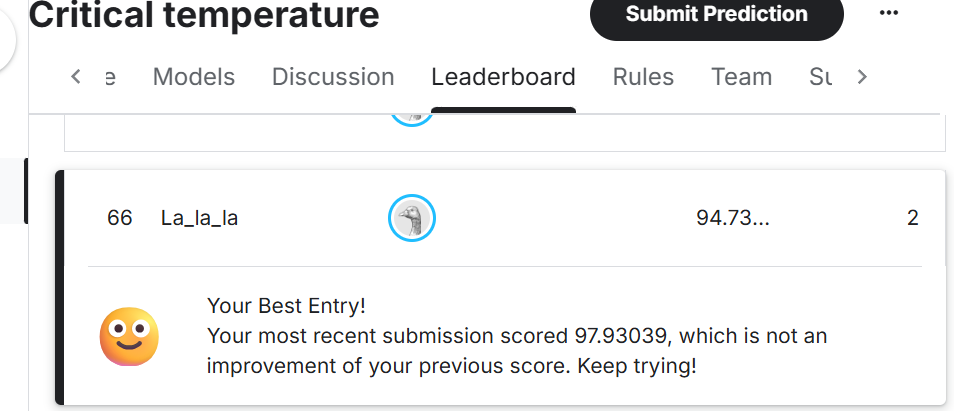